# Main Models for Rating Prediction (1–5) on Cold-Start Recipes: M1 and M3

This notebook builds the main models for the **main task**: predict the rating (1–5) a user gives a recipe that has **no reviews in the training data**, evaluated with **MSE** on cold rows. It uses exactly the same training rows, features and evaluation protocol as the baselines in `03_baselines_rating.ipynb`.

| | Model | Features |
|---|---|---|
| M1 | Ridge regression | all groups A + B + C + D |
| M3 | LightGBM regression | all groups A + B + C + D |

**The bar** (from the baselines): beat **B2** (user features) on MSE with a paired bootstrap CI that excludes 0, and beat **B3** (TF-IDF cosine) on Hit@10 / NDCG@10.

Section 7 repeats M1 and M3 for the supplementary binary target (rating == 5, evaluated with AUC).

Hyperparameters are chosen on the **validation** cold rows (2013). In Section 6 every model is refit on train + validation and evaluated **once** on the test split (2014–2018).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import features as F
import evaluate as E
import plots as P

P.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Data and features

All features are looked up by id and computed with `features.build_features`. History-based features use only reviews dated **strictly before** each row's date (training rows see their own past, validation rows see train, test rows see train + validation).

| Group | Content | Prefix |
|---|---|---|
| A. recipe content | log minutes, steps, ingredients, nutrition, cleaning flags, calorie level, submission year, description length, top-300 tags (multi-hot), **recipe age** at review time | — |
| B. user history | # past ratings, mean rating (raw and smoothed), std, 5-star share (raw and smoothed) | `u_` |
| C. user × recipe match | cosine / Jaccard / max similarity to the user's past (and 5-star) recipes over tags, ingredients, techniques and all three; 5-star share and mean rating of the k most similar past recipes (k = 5, 10, 20, 50); distance in minutes and calories; TF-IDF cosine to past recipes (the B3 features); the k-NN and TF-IDF features enter **relative to the user** (Section 1.1) | `m_`, `t_` |
| D. author | number of earlier reviews of the author's other recipes, their smoothed 5-star share and mean rating, number of recipes posted | `a_` |

In [2]:
splits, recipes = F.load_data()
train, valid, test = splits["train"], splits["validation"], splits["test"]

# content representations use recipe content only (no ratings), so they can be built from all recipes
tag_vocab = F.top_vocab(recipes.tags, F.N_TAGS)
content = F.content_matrix(recipes, tag_vocab, F.top_vocab(recipes.ingredients, F.N_INGREDIENTS))
X_text = F.tfidf_matrix(recipes)
recipe_feats = F.recipe_features(recipes, tag_vocab)

def featurize(rows, history):
    return F.build_features(rows, history, recipes, content, recipe_feats=recipe_feats, tfidf=X_text).astype(np.float32)

def training_set(history):
    # pseudo-cold rows: reviews on the first day a recipe was reviewed, by users with >= 3 earlier ratings
    rows = F.pseudo_cold_rows(history)
    feats = featurize(rows, history)
    keep = (feats.u_n >= F.MIN_PRIOR).values
    return rows[keep], feats[keep], F.training_weights(rows.user_id.values[keep])

train_rows, train_feats, train_w = training_set(train)
valid_feats = featurize(valid, train)
cold = (valid.cold == 1).values
y_valid = valid.rating.values.astype(float)
users_valid = valid.user_id.values
print(f"training rows: {len(train_rows):,}; validation cold rows: {cold.sum()} ({len(set(users_valid[cold]))} users)")

training rows: 151,945; validation cold rows: 6410 (859 users)


In [3]:
def group_of(col):
    if col.startswith("u_"):
        return "B"
    if col.startswith(("m_", "t_")):
        return "C"
    if col.startswith("a_"):
        return "D"
    return "A"

GROUP_NAMES = {"A": "A recipe content", "B": "B user history", "C": "C user x recipe match", "D": "D author"}
GROUP_COLORS = dict(zip("ABCD", P.SERIES))
import re
# the raw k-NN features and t_cos_liked are replaced by their versions relative to the user (Section 1.1)
REPLACED = [c for c in train_feats.columns if re.fullmatch(r"m_\w+_knn\d+(_rating)?", c)] + ["t_cos_liked"]
COLS = [c for c in train_feats.columns if c not in REPLACED]
groups = pd.Series({c: group_of(c) for c in COLS})
print(f"{len(COLS)} features:", ", ".join(f"{GROUP_NAMES[g]} {n}" for g, n in groups.value_counts().sort_index().items()))

384 features: A recipe content 321, B user history 6, C user x recipe match 53, D author 4


### 1.1 Redundant features and the relative k-NN features

A correlation check on the training rows shows that several engineered features repeat each other. Most importantly, the k-NN features of group C, the mean rating (or 5-star share) the user gave to the k past recipes most similar to this one, are almost the same number as the user's overall average: with k = 50 most users' "nearest" recipes are a large part of everything they rated. They then carry little information about *this* recipe and mostly repeat group B.

We therefore use them **relative to the user**: `m_<space>_knn<K>_rating_dev` = k-NN mean rating − `u_mean`, and `m_<space>_knn<K>_dev` = k-NN 5-star share − `u_rate`, i.e. how much more (or less) generous the user has been with this kind of recipe than usual. Likewise `t_cos_diff` = `t_cos_liked` − `t_cos_all` (B3's two similarities had opposite signs, so this difference is what it learned). The raw versions are dropped from the main models; B3 still uses its own two similarities.

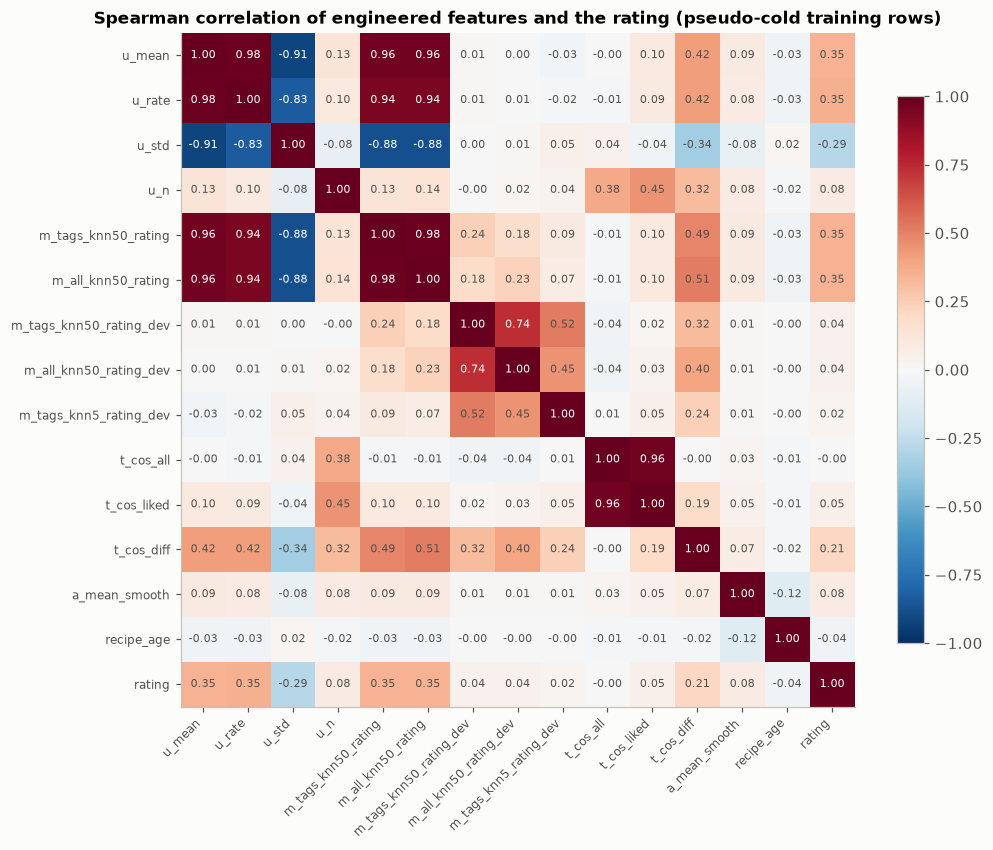

correlation with u_mean: m_tags_knn50_rating 0.96, m_tags_knn50_rating_dev 0.01, m_all_knn50_rating_dev 0.00
384 features used by the main models (33 raw k-NN / TF-IDF columns replaced by relative ones)


In [4]:
show = ["u_mean", "u_rate", "u_std", "u_n", "m_tags_knn50_rating", "m_all_knn50_rating", "m_tags_knn50_rating_dev",
        "m_all_knn50_rating_dev", "m_tags_knn5_rating_dev", "t_cos_all", "t_cos_liked", "t_cos_diff", "a_mean_smooth", "recipe_age"]
corr = train_feats[show].assign(rating=train_rows.rating.values).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 7.8))
im = P.heatmap(ax, corr, title="Spearman correlation of engineered features and the rating (pseudo-cold training rows)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
print("correlation with u_mean:", ", ".join(f"{c} {corr.loc['u_mean', c]:.2f}" for c in ["m_tags_knn50_rating", "m_tags_knn50_rating_dev", "m_all_knn50_rating_dev"]))
print(f"{len(COLS)} features used by the main models ({len(REPLACED)} raw k-NN / TF-IDF columns replaced by relative ones)")

**Reading the heatmap.** The top-left block is group B plus the raw k-NN ratings: `u_mean`, `u_rate` and `m_*_knn50_rating` correlate 0.94–0.98 with each other, so the raw k-NN ratings are essentially a copy of the user's rating level. After subtracting `u_mean`, their correlation with it drops to 0.00–0.01: what is left is the part that is specific to this kind of recipe. The bottom row shows how weak that part is: the deviations correlate only 0.02–0.04 with the rating, against 0.35 for the user's mean, and the TF-IDF similarities 0.00–0.05 on their own. `t_cos_diff` reaches 0.21, but it is also correlated with the user's level (0.42 with `u_mean`), because users who love a narrow set of recipes rate them highly. Recipe-specific signal is therefore small, which is consistent with the small gains over B2 below.

## 2. Reference baselines

B0, B2 and B3 are refit here with the same code as in `03_baselines_rating.ipynb`, so the main models can be compared with them on the same rows (paired bootstrap). B1 is left out: on cold rows it is statistically indistinguishable from B2.

In [5]:
USER_COLS = ["u_n", "u_mean", "u_mean_smooth", "u_std", "u_rate"]

def b2_matrix(feats):
    return feats[USER_COLS].assign(u_n=np.log1p(feats.u_n))

def b3_matrix(feats):
    liked = feats.t_cos_liked.fillna(feats.t_cos_all)     # user without 5-star history: fall back to all recipes
    return pd.DataFrame({"t_cos_all": feats.t_cos_all.fillna(0), "t_cos_liked": liked.fillna(0)})

def fit_small_ridge(matrix, rows, feats, w):
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(matrix(feats), rows.rating, ridge__sample_weight=w)
    return lambda f: model.predict(matrix(f))

def fit_baselines(rows, feats, w, history):
    mean = history.rating.mean()
    return {"B0 global mean": lambda f: np.full(len(f), mean),
            "B2 user features": fit_small_ridge(b2_matrix, rows, feats, w),
            "B3 TF-IDF cosine": fit_small_ridge(b3_matrix, rows, feats, w)}

results, preds = {}, {}
def report(name, pred):
    preds[name] = np.clip(np.asarray(pred, dtype=float), 1, 5)
    results[name] = r = E.evaluate_rating(y_valid[cold], preds[name][cold], users_valid[cold])
    print(f"{name}: validation cold MSE {r['MSE']:.4f} (95% CI {r['CI low']:.4f}-{r['CI high']:.4f}), MAE {r['MAE']:.4f}")

def val_mse(pred):
    return E.evaluate_rating(y_valid[cold], pred[cold], users_valid[cold], n_boot=1)["MSE"]

def print_diffs(table, col="MSE diff"):
    for name, r in table.iterrows():
        print(f"{name}: {r[col]:+.4f} (95% CI {r['CI low']:+.4f} to {r['CI high']:+.4f})")

for name, predict in fit_baselines(train_rows, train_feats, train_w, train).items():
    report(name, predict(valid_feats))

B0 global mean: validation cold MSE 0.3532 (95% CI 0.3088-0.4008), MAE 0.4589


B2 user features: validation cold MSE 0.3081 (95% CI 0.2716-0.3494), MAE 0.3847


B3 TF-IDF cosine: validation cold MSE 0.3439 (95% CI 0.3029-0.3883), MAE 0.4616


## 3. M1: Ridge regression on all features

A linear model on all four groups, trained with weighted squared error plus an L2 penalty:

$$\min_\theta \sum_{(u,i)} w_u \,(r_{u,i} - \theta^\top x_{u,i})^2 + \lambda \lVert\theta\rVert^2, \qquad w_u = 1/\sqrt{n_u}$$

Preprocessing:
- **missing values** (e.g. the k-NN features of a user with no 5-star history) are filled with the training median, and a 0/1 "was missing" column is added;
- **counts** (`u_n`, `a_n`, `a_recipes`, description length) are log-transformed;
- every column is standardized, so coefficients are comparable.

The penalty $\lambda$ is chosen on the validation cold rows.

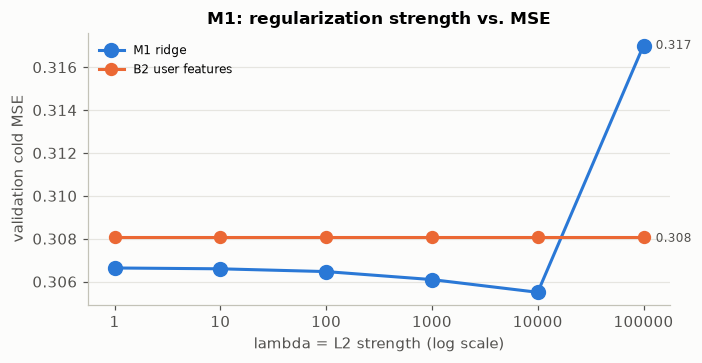

best lambda = 10,000
M1 ridge: validation cold MSE 0.3055 (95% CI 0.2705-0.3472), MAE 0.3961


In [6]:
COUNT_COLS = ["u_n", "a_n", "a_recipes", "description_words"]

def linear_inputs(feats, cols):
    X = feats[cols].copy()
    for c in set(COUNT_COLS) & set(cols):
        X[c] = np.log1p(X[c])
    return X.values

def fit_m1(rows, feats, w, cols, alpha):
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge(alpha=alpha))
    model.fit(linear_inputs(feats, cols), rows.rating.values, ridge__sample_weight=w)
    predict = lambda f: model.predict(linear_inputs(f, cols))
    predict.model, predict.cols = model, cols
    return predict

m1_grid = []
for alpha in [1, 10, 100, 1_000, 10_000, 100_000]:
    predict = fit_m1(train_rows, train_feats, train_w, COLS, alpha)
    m1_grid.append({"alpha": alpha, "predict": predict, "p": predict(valid_feats)})
    m1_grid[-1]["cold MSE"] = val_mse(m1_grid[-1]["p"])

fig, ax = plt.subplots(figsize=(6.5, 3.4))
P.lines(ax, [r["alpha"] for r in m1_grid], {"M1 ridge": [r["cold MSE"] for r in m1_grid],
                                            "B2 user features": [results["B2 user features"]["MSE"]] * len(m1_grid)},
        "lambda = L2 strength (log scale)", "validation cold MSE", title="M1: regularization strength vs. MSE", xlog=True)
plt.tight_layout(); plt.show()

best_m1 = min(m1_grid, key=lambda r: r["cold MSE"])
print(f"best lambda = {best_m1['alpha']:,}")
report("M1 ridge", best_m1["p"])

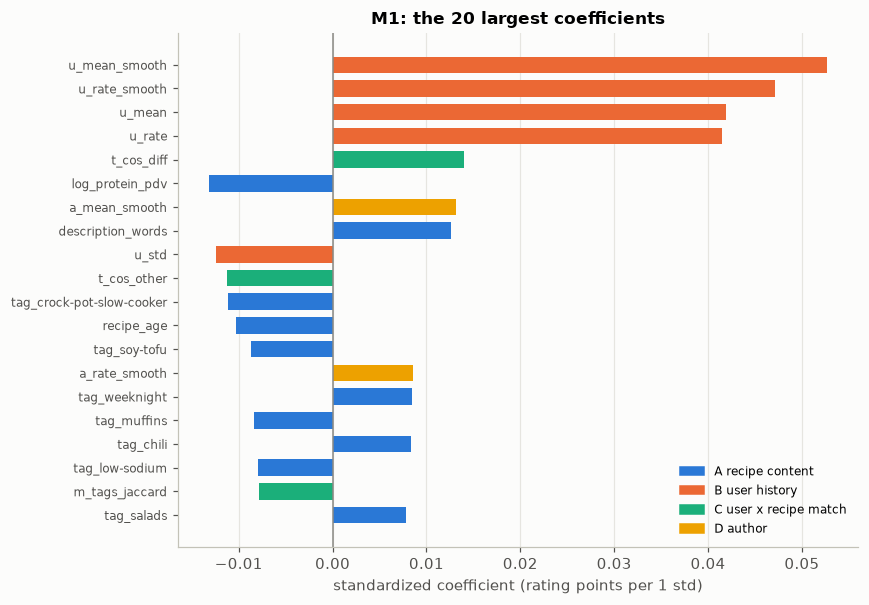

In [7]:
def coefficient_names(predict):
    imputer = predict.model[0]
    names = imputer.get_feature_names_out(predict.cols)
    return [n.replace("missingindicator_", "") + (" (missing)" if n.startswith("missingindicator_") else "") for n in names]

coef = pd.Series(best_m1["predict"].model[-1].coef_, index=coefficient_names(best_m1["predict"]))
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:20])[::-1]
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(range(len(top)), top.values, color=[GROUP_COLORS[group_of(n)] for n in top.index], height=0.7)
ax.set_yticks(range(len(top)), top.index, fontsize=8)
ax.axvline(0, color=P.GRAY, linewidth=1)
ax.set_xlabel("standardized coefficient (rating points per 1 std)")
ax.set_title("M1: the 20 largest coefficients")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GROUP_COLORS[g]) for g in "ABCD"],
          labels=[GROUP_NAMES[g] for g in "ABCD"], frameon=False, fontsize=8, loc="lower right")
ax.grid(True, axis="x"); ax.grid(False, axis="y")
plt.tight_layout(); plt.show()

**Reading M1.** The validation MSE falls slowly as $\lambda$ grows, reaches its minimum at $\lambda$ = 10,000 (0.3055) and rises sharply at 100,000; every setting up to 10,000 is below B2 (0.3081). The largest coefficients belong to the user group (`u_mean_smooth`, `u_rate_smooth`, `u_mean`, `u_rate`). Next come `t_cos_diff` (closer to the recipes the user loved than to the ones they usually cook → higher rating), protein (−), the author's past mean rating (+), description length (+), crock-pot recipes (−) and recipe age (−). The content effects agree with the EDA (e.g. crock-pot recipes are rated lower, older recipes slightly lower). Every effect is small: one standard deviation of any feature moves the prediction by at most about 0.05 stars.

## 4. M3: LightGBM regression on all features

Gradient-boosted trees with squared loss and the same sample weights. Trees handle missing values natively and need no scaling or log transforms, and they can learn non-linear effects and interactions (e.g. "this user is strict *and* the recipe is unlike anything they loved").

To keep the search small (a large grid would start to fit the noise of the validation rows), we fix the learning rate (0.03), row subsampling (0.8) and column subsampling (0.5), and tune only the tree size (`num_leaves`), the minimum rows per leaf (`min_child_samples`) and the number of trees. Each configuration is trained once with 1,500 trees and evaluated after 100, 200, …, 1,500 trees.

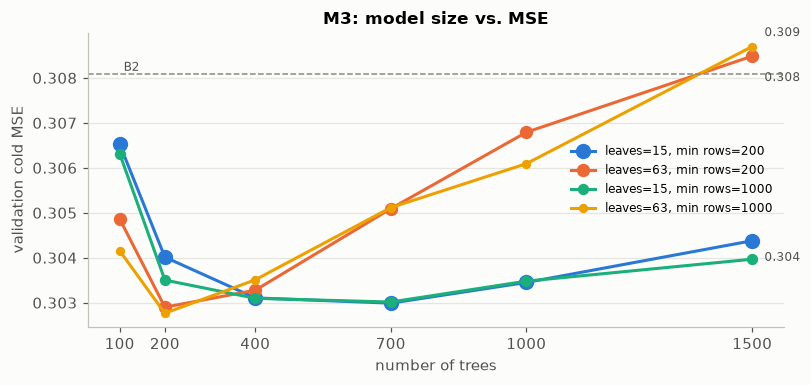

best M3 settings: {'num_leaves': 63, 'min_child_samples': 1000, 'n_estimators': 200}
M3 LightGBM: validation cold MSE 0.3028 (95% CI 0.2675-0.3435), MAE 0.3890


In [8]:
LGB_BASE = dict(objective="regression", learning_rate=0.03, n_estimators=1500, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.5, reg_lambda=1.0, random_state=0, verbose=-1)

def fit_m3(rows, feats, w, cols, **params):
    model = lgb.LGBMRegressor(**{**LGB_BASE, **params})
    model.fit(feats[cols].values, rows.rating.values, sample_weight=w)
    predict = lambda f, n_trees=None: model.predict(f[cols].values, num_iteration=n_trees)
    predict.model, predict.cols = model, cols
    return predict

TREES = [100, 200, 400, 700, 1000, 1500]
m3_grid = []
for params in [dict(num_leaves=15, min_child_samples=200), dict(num_leaves=63, min_child_samples=200),
               dict(num_leaves=15, min_child_samples=1000), dict(num_leaves=63, min_child_samples=1000)]:
    predict = fit_m3(train_rows, train_feats, train_w, COLS, **params)
    mse = [val_mse(predict(valid_feats, n)) for n in TREES]
    m3_grid.append({"params": params, "predict": predict, "mse": mse})

fig, ax = plt.subplots(figsize=(7.5, 3.6))
P.lines(ax, TREES, {f"leaves={r['params']['num_leaves']}, min rows={r['params']['min_child_samples']}": r["mse"]
                    for r in m3_grid}, "number of trees", "validation cold MSE", title="M3: model size vs. MSE")
ax.axhline(results["B2 user features"]["MSE"], color=P.GRAY, linestyle="--", linewidth=1)
ax.text(TREES[0], results["B2 user features"]["MSE"], " B2", va="bottom", fontsize=8, color=P.INK)
plt.tight_layout(); plt.show()

best_r, best_j = min(((r, j) for r in m3_grid for j in range(len(TREES))), key=lambda t: t[0]["mse"][t[1]])
best_m3 = {**best_r["params"], "n_estimators": TREES[best_j]}
print("best M3 settings:", best_m3)
report("M3 LightGBM", best_r["predict"](valid_feats, TREES[best_j]))

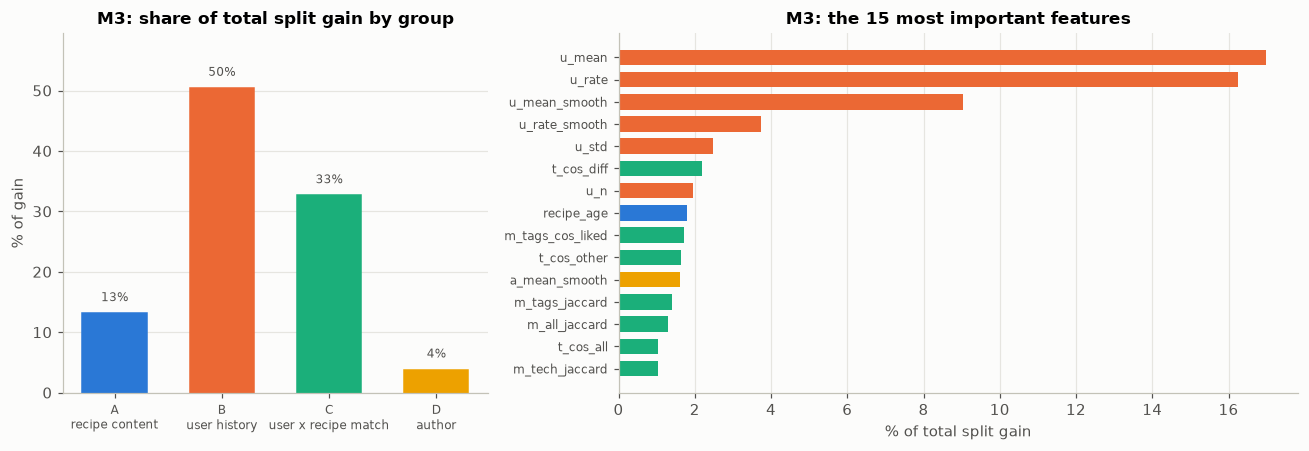

In [9]:
m3_val = fit_m3(train_rows, train_feats, train_w, COLS, **best_m3)
gain = pd.Series(m3_val.model.booster_.feature_importance("gain"), index=COLS)
gain = gain / gain.sum() * 100
by_group = gain.groupby(groups).sum().reindex(list("ABCD"))
top = gain.sort_values(ascending=False)[:15][::-1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
P.bars(axes[0], [GROUP_NAMES[g] for g in by_group.index], by_group.values, fmt="{:.0f}%",
       title="M3: share of total split gain by group", ylabel="% of gain")
for patch, g in zip(axes[0].patches, by_group.index):
    patch.set_color(GROUP_COLORS[g])
axes[1].barh(range(len(top)), top.values, color=[GROUP_COLORS[group_of(n)] for n in top.index], height=0.7)
axes[1].set_yticks(range(len(top)), top.index, fontsize=8)
axes[1].set_xlabel("% of total split gain")
axes[1].set_title("M3: the 15 most important features")
axes[1].grid(True, axis="x"); axes[1].grid(False, axis="y")
plt.tight_layout(); plt.show()

**Reading M3.** At its best number of trees every setting beats B2 (0.3081) on validation. Large models overfit as trees are added (63 leaves reach their best at 200 trees and are worse than B2 by 1,500), while the smaller settings (15 leaves) stay flat around 0.303. The chosen setting is 63 leaves, 1,000 rows per leaf and 200 trees (0.3028). The trees spend 50% of their split gain on the user group and 33% on the match group. With the raw k-NN ratings (before Section 1.1) the split was 38% user / 44% match: the trees had been crediting the match group for what was really the user's rating level, so feature importance alone would have overstated group C.

## 5. Validation results

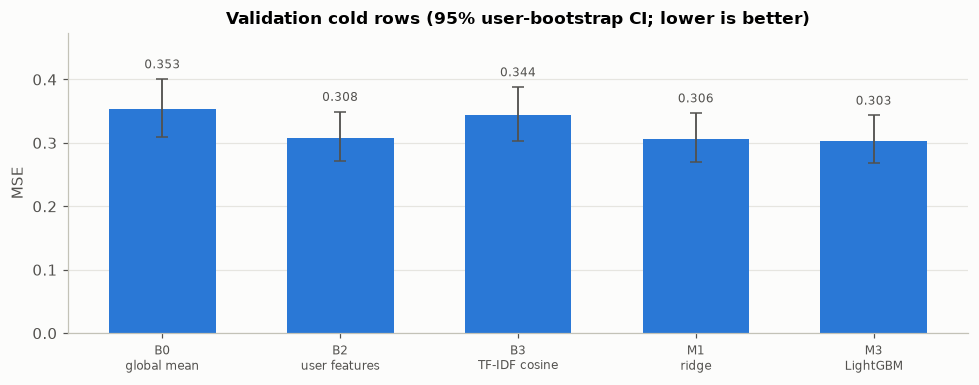

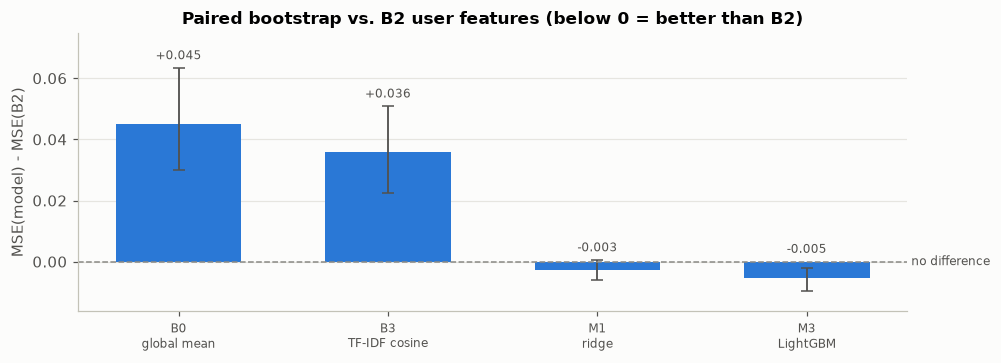

B0 global mean: +0.0451 (95% CI +0.0300 to +0.0633)
B3 TF-IDF cosine: +0.0358 (95% CI +0.0226 to +0.0508)
M1 ridge: -0.0026 (95% CI -0.0060 to +0.0005)
M3 LightGBM: -0.0053 (95% CI -0.0095 to -0.0021)


In [10]:
table = pd.DataFrame(results).T
fig, ax = plt.subplots(figsize=(9, 3.6))
P.bars(ax, table.index, table["MSE"], table["CI low"], table["CI high"],
       title="Validation cold rows (95% user-bootstrap CI; lower is better)", ylabel="MSE")
plt.tight_layout(); plt.show()

b2_name = "B2 user features"
diff = pd.DataFrame({name: E.compare_rating(y_valid[cold], preds[name][cold], preds[b2_name][cold], users_valid[cold])
                     for name in preds if name != b2_name}).T
P.diff_bars(diff, "MSE diff", f"Paired bootstrap vs. {b2_name} (below 0 = better than B2)", "MSE(model) - MSE(B2)")
print_diffs(diff)

On the validation cold rows M3 is significantly better than B2: the paired difference is −0.0053 (95% CI −0.0095 to −0.0021), about 1.7% of B2's MSE. M1 is −0.0026 (−0.0060 to +0.0005), better on average but not significantly.

### Group ablation

Which groups carry the signal? Each model is refit with the hyperparameters chosen above on a subset of groups, always including the user group B (without it, a cold-start model cannot know how generous a user is). The last setting removes `recipe_age`, whose distribution differs most between training and evaluation rows (median 0.40 vs. 0.65 years), to check whether the models extrapolate badly on it.

Each bar is the paired difference MSE(setting) − MSE(B2) on the validation cold rows.

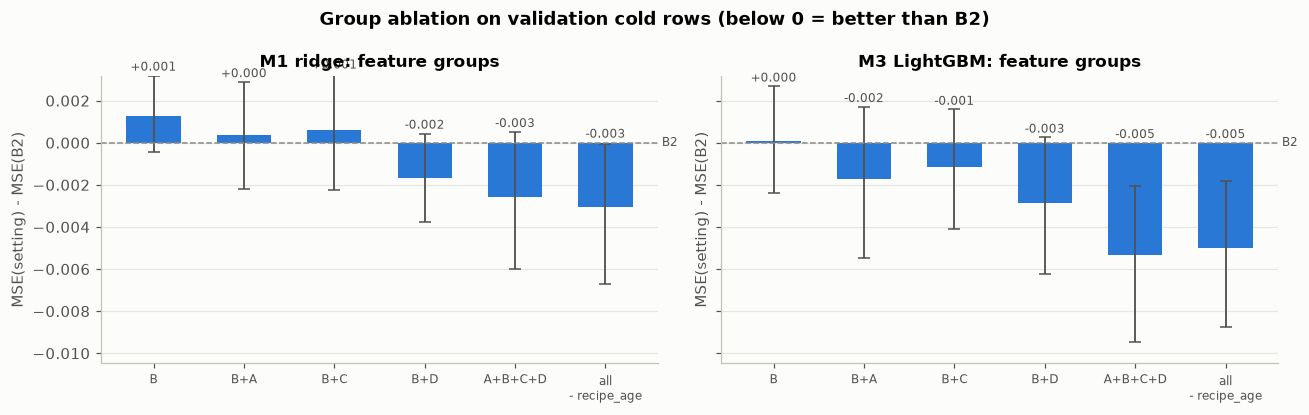

M1 ridge
B: +0.0013 (95% CI -0.0004 to +0.0032)
B+A: +0.0004 (95% CI -0.0022 to +0.0029)
B+C: +0.0006 (95% CI -0.0022 to +0.0033)
B+D: -0.0017 (95% CI -0.0038 to +0.0004)
A+B+C+D: -0.0026 (95% CI -0.0060 to +0.0005)
all - recipe_age: -0.0031 (95% CI -0.0067 to -0.0001)
M3 LightGBM
B: +0.0001 (95% CI -0.0024 to +0.0027)
B+A: -0.0017 (95% CI -0.0055 to +0.0017)
B+C: -0.0011 (95% CI -0.0041 to +0.0016)
B+D: -0.0029 (95% CI -0.0062 to +0.0003)
A+B+C+D: -0.0053 (95% CI -0.0095 to -0.0021)
all - recipe_age: -0.0050 (95% CI -0.0088 to -0.0018)


In [11]:
SETTINGS = {"B": "B", "B+A": "AB", "B+C": "BC", "B+D": "BD", "A+B+C+D": "ABCD"}
setting_cols = {name: [c for c in COLS if groups[c] in g] for name, g in SETTINGS.items()}
setting_cols["all - recipe_age"] = [c for c in COLS if c != "recipe_age"]

ablation = {"M1 ridge": {}, "M3 LightGBM": {}}
for name, cols in setting_cols.items():
    fits = {"M1 ridge": fit_m1(train_rows, train_feats, train_w, cols, best_m1["alpha"]),
            "M3 LightGBM": fit_m3(train_rows, train_feats, train_w, cols, **best_m3)}
    for model, predict in fits.items():
        p = np.clip(predict(valid_feats), 1, 5)
        ablation[model][name] = E.compare_rating(y_valid[cold], p[cold], preds[b2_name][cold], users_valid[cold])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (model, rows) in zip(axes, ablation.items()):
    t = pd.DataFrame(rows).T
    P.bars(ax, t.index, t["MSE diff"], t["CI low"], t["CI high"], ref=0, ref_label="B2", fmt="{:+.3f}",
           title=f"{model}: feature groups", ylabel="MSE(setting) - MSE(B2)")
fig.suptitle("Group ablation on validation cold rows (below 0 = better than B2)", fontweight="bold")
plt.tight_layout(); plt.show()
for model, rows in ablation.items():
    print(model); print_diffs(pd.DataFrame(rows).T)

For both models, no single group added to B moves the MSE significantly; the largest single gain comes from the author group D (M1 −0.0017, M3 −0.0029, both CIs touching 0). M3 only becomes significantly better than B2 when all groups are combined (−0.0053), which suggests that the trees use interactions between groups rather than any one group on its own. Removing `recipe_age` does not hurt (M1 −0.0031, M3 −0.0050), so the shift in recipe age between training and evaluation rows causes no extrapolation problem.

## 6. Test split

Every model is refit with the settings chosen above, now on **train + validation** (pseudo-cold training rows, user and author features), and evaluated **once** on the 4,099 test cold rows (2014–2018).

- **MSE** with a user-bootstrap 95% CI, and the paired difference against B2;
- **AUC** of the predicted rating for `rating == 5`, and **Hit@10 / NDCG@10**: each 5-star cold test review is ranked against 99 cold recipes the user never reviewed (no reviews in train + validation, already submitted at the review date). Ranking uses the unclipped prediction, since clipping at 5 would create artificial ties;
- errors **by true rating**, **by length of the user's history**, and on **warm vs. cold** rows.

In [12]:
full = pd.concat([train, valid], ignore_index=True)
final_rows, final_feats, final_w = training_set(full)
test_feats = featurize(test, full)
test_cold = (test.cold == 1).values
y_test = test.rating.values.astype(float)
users_test = test.user_id.values

reviewed = pd.concat([train, valid, test]).groupby("user_id").recipe_id.agg(set).to_dict()
cold_pool = recipes.index[~recipes.index.isin(full.recipe_id)]
positives = test[test_cold & (test.rating == 5)]
cands = E.sample_candidates(positives, cold_pool, reviewed, recipes.submitted)
cand_feats = featurize(cands, full)

final = fit_baselines(final_rows, final_feats, final_w, full)
final["M1 ridge"] = fit_m1(final_rows, final_feats, final_w, COLS, best_m1["alpha"])
final["M3 LightGBM"] = fit_m3(final_rows, final_feats, final_w, COLS, **best_m3)
print(f"final training rows: {len(final_rows):,}; test cold rows: {test_cold.sum()}; ranking lists: {len(positives)} x 100")

final training rows: 156,779; test cold rows: 4099; ranking lists: 3263 x 100


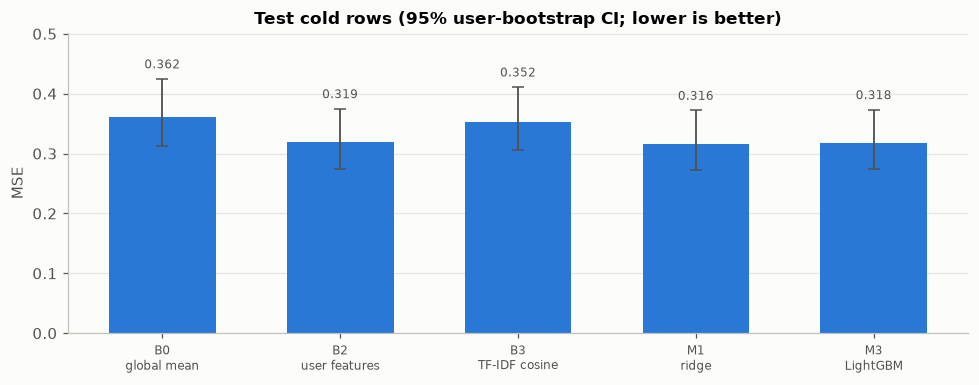

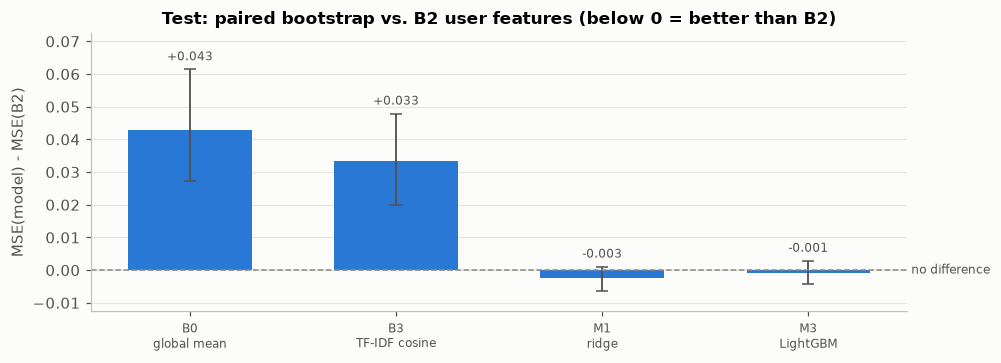

B0 global mean: +0.0430 (95% CI +0.0274 to +0.0614)
B3 TF-IDF cosine: +0.0332 (95% CI +0.0199 to +0.0479)
M1 ridge: -0.0025 (95% CI -0.0063 to +0.0011)
M3 LightGBM: -0.0008 (95% CI -0.0041 to +0.0028)


In [13]:
test_pred = {name: np.clip(predict(test_feats), 1, 5) for name, predict in final.items()}
test_mse, test_rank, rank_rows = {}, {}, {}
for name, predict in final.items():
    p = test_pred[name]
    test_mse[name] = E.evaluate_rating(y_test[test_cold], p[test_cold], users_test[test_cold])
    auc = E.evaluate((y_test[test_cold] == 5).astype(int), p[test_cold], users_test[test_cold], is_prob=False)
    rank_rows[name] = rank = E.ranking_metrics(cands, predict(cand_feats))
    hit = E.mean_ci(rank["Hit@10"], positives.user_id.values)
    ndcg = E.mean_ci(rank["NDCG@10"], positives.user_id.values)
    test_rank[name] = {"AUC": auc["AUC"], "AUC low": auc["CI low"], "AUC high": auc["CI high"],
                       "Hit@10": hit[0], "Hit@10 low": hit[1], "Hit@10 high": hit[2],
                       "NDCG@10": ndcg[0], "NDCG@10 low": ndcg[1], "NDCG@10 high": ndcg[2]}
test_mse, test_rank = pd.DataFrame(test_mse).T, pd.DataFrame(test_rank).T

fig, ax = plt.subplots(figsize=(9, 3.6))
P.bars(ax, test_mse.index, test_mse["MSE"], test_mse["CI low"], test_mse["CI high"],
       title="Test cold rows (95% user-bootstrap CI; lower is better)", ylabel="MSE")
plt.tight_layout(); plt.show()

test_diff = pd.DataFrame({name: E.compare_rating(y_test[test_cold], test_pred[name][test_cold],
                                                 test_pred[b2_name][test_cold], users_test[test_cold])
                          for name in final if name != b2_name}).T
P.diff_bars(test_diff, "MSE diff", f"Test: paired bootstrap vs. {b2_name} (below 0 = better than B2)", "MSE(model) - MSE(B2)")
print_diffs(test_diff)

On the test split both models are slightly better than B2 but not significantly: M1 −0.0025 (95% CI −0.0063 to +0.0011) and M3 −0.0008 (−0.0041 to +0.0028), i.e. 0.8% and 0.3% of B2's MSE (0.319). The validation improvement of M3 is therefore not confirmed on test.

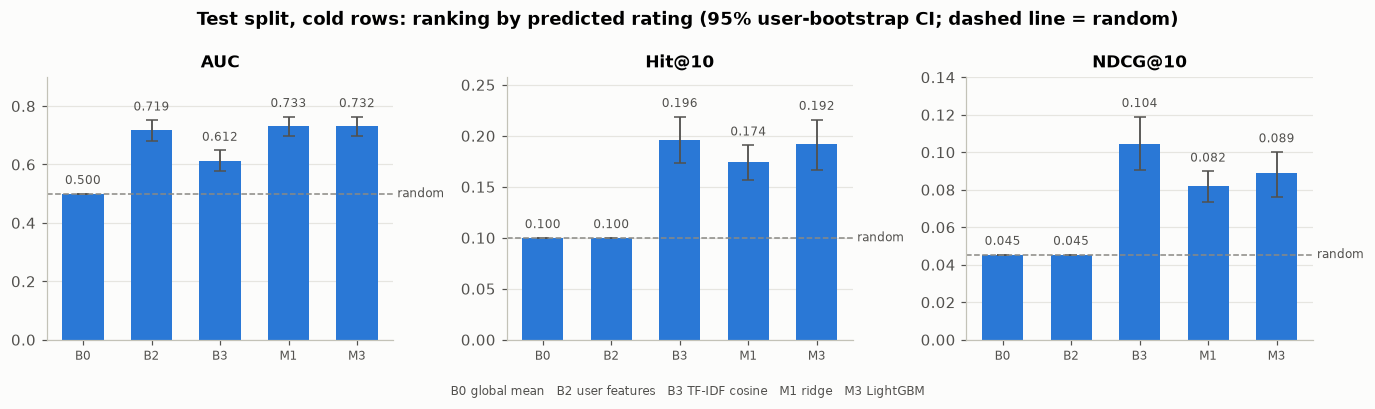

M1 ridge - B3, Hit@10: -0.022 (95% CI -0.050 to +0.005)
M1 ridge - B3, NDCG@10: -0.022 (95% CI -0.039 to -0.006)
M3 LightGBM - B3, Hit@10: -0.004 (95% CI -0.040 to +0.030)
M3 LightGBM - B3, NDCG@10: -0.016 (95% CI -0.037 to +0.003)


In [14]:
random_ndcg = E.ranking_metrics(cands, np.zeros(len(cands)))["NDCG@10"].mean()
P.metric_bars(test_rank, ["AUC", "Hit@10", "NDCG@10"], refs={"AUC": 0.5, "Hit@10": 0.1, "NDCG@10": random_ndcg},
              suptitle="Test split, cold rows: ranking by predicted rating (95% user-bootstrap CI; dashed line = random)")

# paired difference against B3 on the same candidate lists
vs_b3 = {}
for name in ["M1 ridge", "M3 LightGBM"]:
    for m in ["Hit@10", "NDCG@10"]:
        d = rank_rows[name][m].values - rank_rows["B3 TF-IDF cosine"][m].values
        vs_b3[(name, m)] = E.mean_ci(d, positives.user_id.values)
for (name, m), (d, lo, hi) in vs_b3.items():
    print(f"{name} - B3, {m}: {d:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")

**Ranking.** Both main models rank a user's candidates far better than random (Hit@10 0.174 for M1, 0.192 for M3, vs. 0.100) and are not significantly different from B3 on Hit@10 (M1 −0.022, 95% CI −0.050 to +0.005; M3 −0.004, CI −0.040 to +0.030). On NDCG@10, B3 still places the reviewed recipe slightly higher (M1 −0.022, CI −0.039 to −0.006; M3 −0.016, CI −0.037 to +0.003). At the same time M1 and M3 keep B2's accuracy and reach a higher AUC (0.733 and 0.732 vs. 0.719), so they are the only models that do well on both kinds of metric.

B3 keeps a small edge on NDCG@10 because the ranking task asks *which* recipe a user will review, and closeness to what the user cooks is exactly what B3 measures. M1 and M3 are trained to predict *how high* the rating will be, so features that shift the rating level (recipe age, nutrition, tags) also reorder the candidates.

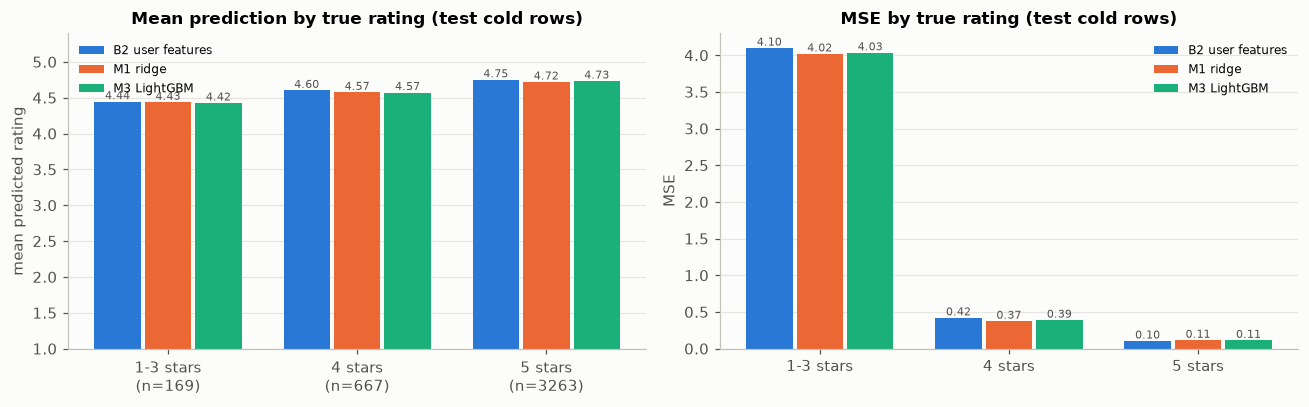

In [15]:
def grouped_bars(ax, categories, series, ylabel, title, fmt="{:.2f}"):
    # one group of bars per category, one bar per model (series: model -> values)
    x, w = np.arange(len(categories)), 0.8 / len(series)
    for k, (color, (name, values)) in enumerate(zip(P.SERIES, series.items())):
        xs = x + (k - (len(series) - 1) / 2) * w
        ax.bar(xs, values, w * 0.92, color=color, label=name)
        for xi, v in zip(xs, values):
            ax.text(xi, v, fmt.format(v), ha="center", va="bottom", fontsize=7, color=P.INK)
    ax.set_xticks(x, categories)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)

SHOW = [b2_name, "M1 ridge", "M3 LightGBM"]
yc = y_test[test_cold]
levels = [(1, 3), (4, 4), (5, 5)]
level_names = [f"{a}" if a == b else f"{a}-{b}" for a, b in levels]
masks = [(yc >= a) & (yc <= b) for a, b in levels]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
grouped_bars(axes[0], [f"{n} stars\n(n={m.sum()})" for n, m in zip(level_names, masks)],
             {name: [test_pred[name][test_cold][m].mean() for m in masks] for name in SHOW},
             "mean predicted rating", "Mean prediction by true rating (test cold rows)")
axes[0].set_ylim(1, 5.4)
grouped_bars(axes[1], [f"{n} stars" for n in level_names],
             {name: [((test_pred[name][test_cold][m] - yc[m]) ** 2).mean() for m in masks] for name in SHOW},
             "MSE", "MSE by true rating (test cold rows)")
plt.tight_layout(); plt.show()

All three models still predict about 4.4 stars for reviews that ended at 1–3 stars (169 rows). The main models gain on the low and 4-star rows (1–3 stars: MSE 4.02 / 4.03 vs. 4.10 for B2; 4 stars: 0.37 / 0.39 vs. 0.42) and lose a little on the 3,263 five-star rows (0.11 vs. 0.10), which is why the overall gain is small.

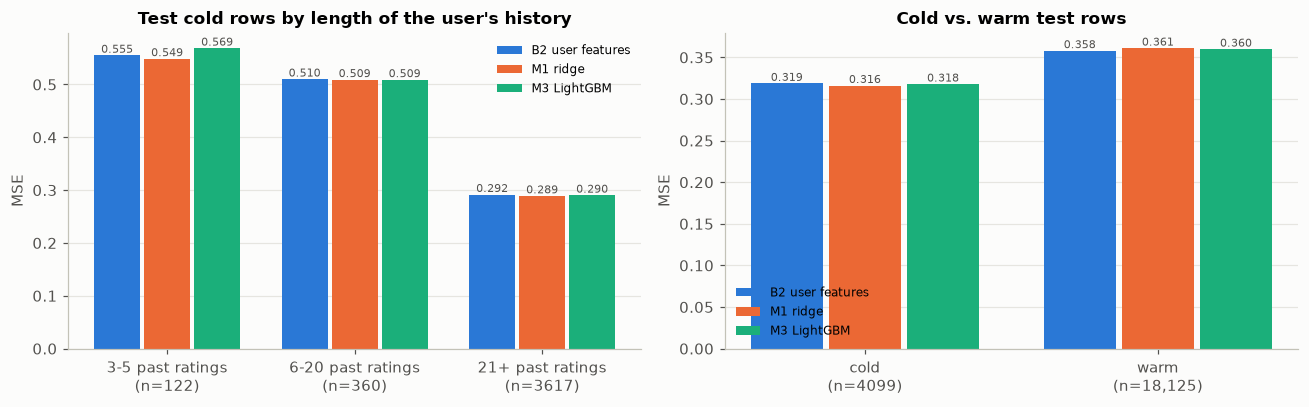

In [16]:
u_n = test_feats.u_n.values
hist_bins = [("3-5", 3, 5), ("6-20", 6, 20), ("21+", 21, np.inf)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
grouped_bars(axes[0], [f"{label} past ratings\n(n={(test_cold & (u_n >= a) & (u_n <= b)).sum()})" for label, a, b in hist_bins],
             {name: [((test_pred[name] - y_test) ** 2)[test_cold & (u_n >= a) & (u_n <= b)].mean() for _, a, b in hist_bins]
              for name in SHOW}, "MSE", "Test cold rows by length of the user's history", fmt="{:.3f}")
grouped_bars(axes[1], [f"cold\n(n={test_cold.sum()})", f"warm\n(n={(~test_cold).sum():,})"],
             {name: [((test_pred[name] - y_test) ** 2)[test_cold].mean(), ((test_pred[name] - y_test) ** 2)[~test_cold].mean()]
              for name in SHOW}, "MSE", "Cold vs. warm test rows", fmt="{:.3f}")
plt.tight_layout(); plt.show()

Users with only 3–5 past ratings are the hardest (MSE about 0.55 on 122 rows), and there M1 is the best (0.549 vs. 0.555 for B2), while M3 is slightly worse (0.569): content features help most when the user history is short, and the linear model uses them more robustly than the trees. For users with 21+ past ratings (88% of rows) all three are within 0.003. Cold and warm test rows give similar errors for all three models, as expected: none of them uses rating statistics of the recipe, so a warm recipe is treated exactly like a cold one.

### Takeaways

- **The user's rating level is most of the signal.** B2 already captures it. Adding 378 recipe, match and author features lowers the validation MSE significantly only for M3 (−1.7%), and on test M1 and M3 are 0.8% and 0.3% better than B2 with intervals that contain 0.
- **The bottleneck is the rare low ratings.** No model can tell in advance which cold recipe a user will dislike: reviews that ended at 1–3 stars are still predicted at about 4.4.
- **The main models combine what each baseline does well.** M1 and M3 are as accurate as B2 (MSE), have a higher AUC, and rank a user's candidates about as well as B3 (Hit@10). No baseline does both.
- **Redundant features mislead importance, not accuracy.** Replacing the raw k-NN ratings (Spearman 0.96 with `u_mean`) by their deviation from the user's mean leaves the accuracy unchanged but moves M3's split gain from the match group back to the user group (Section 1.1).
- **M1 vs. M3.** The two are about equally accurate on test. M1 is simpler, interpretable and more robust for users with short histories; M3 fits validation better but that advantage does not carry over to test.

## 7. Supplementary version: P(rating == 5)

The same task with a binary target: will the user give the cold recipe **5 stars**? The output is a probability in [0, 1], evaluated with **AUC** (the positive rate is about 80%, so accuracy would be meaningless) and log loss. It uses the same pseudo-cold training rows, features and sample weights; only the target ($y = 1$ if rating == 5) and the loss (weighted log loss) change.

| | Model | Features |
|---|---|---|
| B0 | constant (weighted training share of 5 stars) | none |
| B2 | logistic regression, as in `02_baselines_binary.ipynb` | user history |
| M1 | logistic regression with the same preprocessing as the ridge model | A + B + C + D |
| M3 | LightGBM classifier with the same search as the regressor | A + B + C + D |

Hyperparameters are chosen by validation cold AUC. The question this section answers is a **trade-off between targets**: does training directly on "5 stars or not" rank the reviews better than the rating models of Section 6, whose predicted ratings can also be used as a score?

In [17]:
y5_valid = (valid.rating == 5).astype(int).values
B2C_COLS = ["u_n", "u_rate", "u_rate_smooth", "u_mean", "u_std"]   # same as 02_baselines_binary

def b2c_matrix(feats):
    return feats[B2C_COLS].assign(u_n=np.log1p(feats.u_n))

def fit_b2c(rows, feats, w):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(b2c_matrix(feats), rows.y, logisticregression__sample_weight=w)
    return lambda f: model.predict_proba(b2c_matrix(f))[:, 1]

def fit_m1c(rows, feats, w, cols, C):
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                          LogisticRegression(C=C, max_iter=2000))
    model.fit(linear_inputs(feats, cols), rows.y.values, logisticregression__sample_weight=w)
    return lambda f: model.predict_proba(linear_inputs(f, cols))[:, 1]

def fit_m3c(rows, feats, w, cols, **params):
    model = lgb.LGBMClassifier(**{**LGB_BASE, "objective": "binary", **params})
    model.fit(feats[cols].values, rows.y.values, sample_weight=w)
    return lambda f, n_trees=None: model.predict_proba(f[cols].values, num_iteration=n_trees)[:, 1]

def val_auc(score):
    return E.evaluate(y5_valid[cold], score[cold], users_valid[cold], n_boot=1)["AUC"]

bin_results, bin_scores = {}, {}
def report_bin(name, score):
    bin_scores[name] = np.asarray(score, dtype=float)
    bin_results[name] = r = E.evaluate(y5_valid[cold], bin_scores[name][cold], users_valid[cold])
    print(f"{name}: validation cold AUC {r['AUC']:.4f} (95% CI {r['CI low']:.4f}-{r['CI high']:.4f}), log loss {r['log loss']:.4f}")

report_bin("B0 constant", np.full(len(valid), np.average(train_rows.y, weights=train_w)))
report_bin("B2 user features", fit_b2c(train_rows, train_feats, train_w)(valid_feats))

B0 constant: validation cold AUC 0.5000 (95% CI 0.5000-0.5000), log loss 0.5444


B2 user features: validation cold AUC 0.7214 (95% CI 0.6875-0.7558), log loss 0.4760


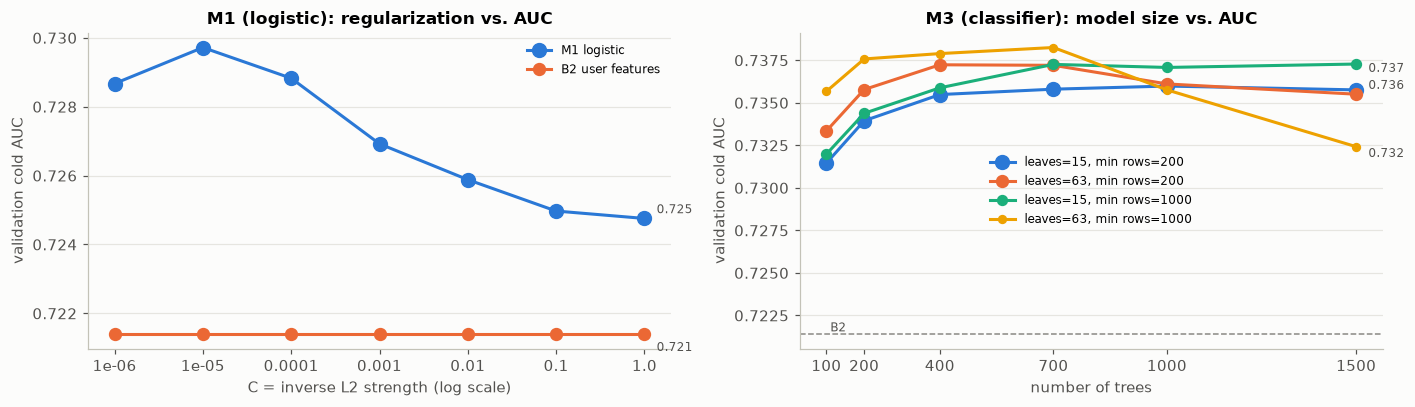

best C = 1e-05; best M3 classifier settings: {'num_leaves': 63, 'min_child_samples': 1000, 'n_estimators': 700}


M1 logistic: validation cold AUC 0.7297 (95% CI 0.7001-0.7607), log loss 0.5199


M3 LightGBM classifier: validation cold AUC 0.7383 (95% CI 0.7074-0.7693), log loss 0.4654


In [18]:
m1c_grid = []
for C in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    s = fit_m1c(train_rows, train_feats, train_w, COLS, C)(valid_feats)
    m1c_grid.append({"C": C, "p": s, "cold AUC": val_auc(s)})

m3c_grid = []
for params in [dict(num_leaves=15, min_child_samples=200), dict(num_leaves=63, min_child_samples=200),
               dict(num_leaves=15, min_child_samples=1000), dict(num_leaves=63, min_child_samples=1000)]:
    predict = fit_m3c(train_rows, train_feats, train_w, COLS, **params)
    m3c_grid.append({"params": params, "predict": predict, "auc": [val_auc(predict(valid_feats, n)) for n in TREES]})

b2_auc = bin_results["B2 user features"]["AUC"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
P.lines(axes[0], [r["C"] for r in m1c_grid], {"M1 logistic": [r["cold AUC"] for r in m1c_grid],
                                              "B2 user features": [b2_auc] * len(m1c_grid)},
        "C = inverse L2 strength (log scale)", "validation cold AUC", title="M1 (logistic): regularization vs. AUC", xlog=True)
P.lines(axes[1], TREES, {f"leaves={r['params']['num_leaves']}, min rows={r['params']['min_child_samples']}": r["auc"]
                         for r in m3c_grid}, "number of trees", "validation cold AUC", title="M3 (classifier): model size vs. AUC")
axes[1].axhline(b2_auc, color=P.GRAY, linestyle="--", linewidth=1)
axes[1].text(TREES[0], b2_auc, " B2", va="bottom", fontsize=8, color=P.INK)
plt.tight_layout(); plt.show()

best_m1c = max(m1c_grid, key=lambda r: r["cold AUC"])
best_r, best_j = max(((r, j) for r in m3c_grid for j in range(len(TREES))), key=lambda t: t[0]["auc"][t[1]])
best_m3c = {**best_r["params"], "n_estimators": TREES[best_j]}
print(f"best C = {best_m1c['C']}; best M3 classifier settings: {best_m3c}")
report_bin("M1 logistic", best_m1c["p"])
report_bin("M3 LightGBM classifier", best_r["predict"](valid_feats, TREES[best_j]))

Both binary models beat B2 on validation (AUC 0.730 for M1, 0.738 for M3, vs. 0.721). The logistic model needs very strong regularization: AUC peaks at C = 0.00001 and falls as the penalty weakens. That choice has a cost the AUC does not show: such a strong penalty shrinks every coefficient towards 0, so the predicted probabilities are squeezed towards the base rate and the log loss gets *worse* (0.520 vs. 0.476 for B2; see the calibration plot below). The classifier is insensitive to its settings (all between 0.732 and 0.738 at their best), so the chosen setting (63 leaves, 1,000 rows per leaf, 700 trees) matters little.

### Test split

All models are refit on train + validation and evaluated once on the 4,099 test cold rows. The rating models of Section 6 (M1 ridge, M3 LightGBM regressor) are included, scored by their predicted rating, so that each main model appears with both targets.

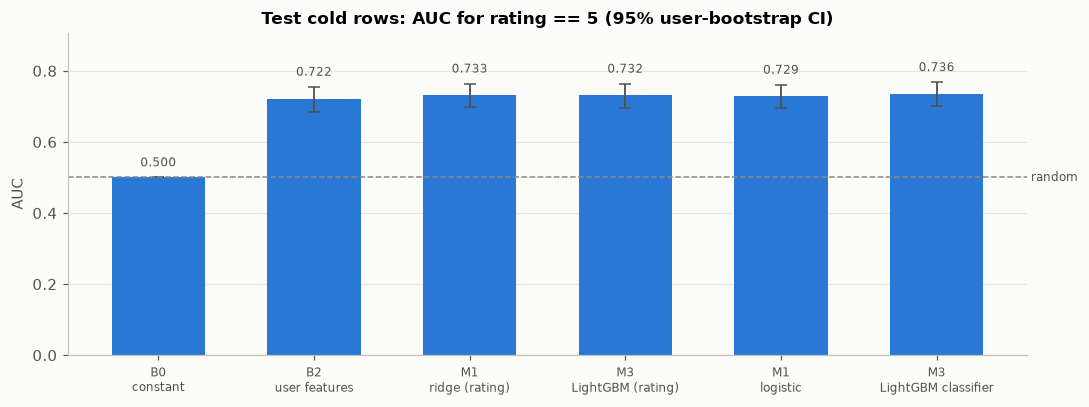

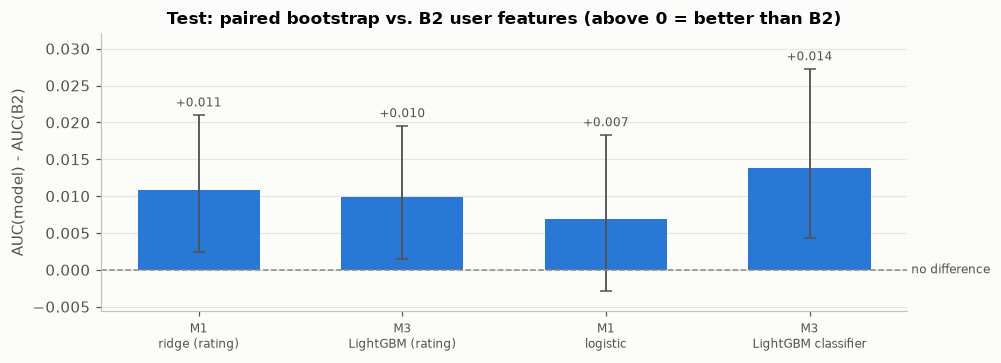

M1 ridge (rating): +0.0108 (95% CI +0.0025 to +0.0210)
M3 LightGBM (rating): +0.0098 (95% CI +0.0015 to +0.0195)
M1 logistic: +0.0069 (95% CI -0.0028 to +0.0183)
M3 LightGBM classifier: +0.0138 (95% CI +0.0043 to +0.0272)

binary target vs. rating target (same features):


M1 logistic - M1 ridge (rating): -0.0038 (95% CI -0.0116 to +0.0034)
M3 LightGBM classifier - M3 LightGBM (rating): +0.0039 (95% CI -0.0028 to +0.0114)

test log loss: B0 constant 0.5264, B2 user features 0.4615, M1 logistic 0.5015, M3 LightGBM classifier 0.4497


In [19]:
y5_test = (test.rating == 5).astype(int).values
p0_final = np.average(final_rows.y, weights=final_w)
final_bin = {"B0 constant": lambda f: np.full(len(f), p0_final),
             "B2 user features": fit_b2c(final_rows, final_feats, final_w),
             "M1 logistic": fit_m1c(final_rows, final_feats, final_w, COLS, best_m1c["C"]),
             "M3 LightGBM classifier": fit_m3c(final_rows, final_feats, final_w, COLS, **best_m3c)}
test_bin = {name: f(test_feats) for name, f in final_bin.items()}
test_bin["M1 ridge (rating)"] = final["M1 ridge"](test_feats)          # unclipped predicted rating as the score
test_bin["M3 LightGBM (rating)"] = final["M3 LightGBM"](test_feats)
order = ["B0 constant", "B2 user features", "M1 ridge (rating)", "M3 LightGBM (rating)", "M1 logistic", "M3 LightGBM classifier"]

yb, ub = y5_test[test_cold], users_test[test_cold]
test_auc = pd.DataFrame({name: E.evaluate(yb, test_bin[name][test_cold], ub) for name in order}).T
fig, ax = plt.subplots(figsize=(10, 3.8))
P.bars(ax, test_auc.index, test_auc["AUC"], test_auc["CI low"], test_auc["CI high"], ref=0.5,
       title="Test cold rows: AUC for rating == 5 (95% user-bootstrap CI)", ylabel="AUC")
plt.tight_layout(); plt.show()

auc_diff = pd.DataFrame({name: E.compare(yb, test_bin[name][test_cold], test_bin["B2 user features"][test_cold], ub)
                         for name in order[2:]}).T
P.diff_bars(auc_diff, "AUC diff", "Test: paired bootstrap vs. B2 user features (above 0 = better than B2)", "AUC(model) - AUC(B2)")
print_diffs(auc_diff, col="AUC diff")

print("\nbinary target vs. rating target (same features):")
target_diff = pd.DataFrame({f"{c} - {r}": E.compare(yb, test_bin[c][test_cold], test_bin[r][test_cold], ub)
                            for c, r in [("M1 logistic", "M1 ridge (rating)"),
                                         ("M3 LightGBM classifier", "M3 LightGBM (rating)")]}).T
print_diffs(target_diff, col="AUC diff")
print("\ntest log loss:", ", ".join(f"{name} {test_auc.loc[name, 'log loss']:.4f}" for name in final_bin))

**AUC detects what MSE could not.** On the test cold rows, three of the four main models are significantly better than B2: the rating models M1 (+0.011, 95% CI +0.003 to +0.021) and M3 (+0.010, +0.002 to +0.020), and the M3 classifier (+0.014, +0.004 to +0.027). The logistic M1 is +0.007 with an interval that contains 0. The same rating models were *not* significantly better than B2 in test MSE (Section 6): the recipe and match features do help to tell which reviews will be 5 stars, but the gain is too small relative to the squared error of the rare low ratings to show up in MSE.

**The target hardly matters for ranking.** With the same features, training on "5 stars or not" instead of the 1–5 rating changes the AUC by −0.004 for M1 (CI −0.012 to +0.003) and +0.004 for M3 (CI −0.003 to +0.011), both within noise. Choosing the rating as the main task therefore costs nothing in ranking ability. The M3 classifier has the lowest test log loss (0.450 vs. 0.462 for B2); the logistic M1 has a worse log loss than B2 (0.502) because of its strong regularization.

### Calibration

Are the predicted probabilities right on average? Test cold rows are grouped into ten equal-size bins by predicted probability, and each bin's mean prediction is plotted against its observed share of 5-star ratings. A calibrated model lies on the diagonal.

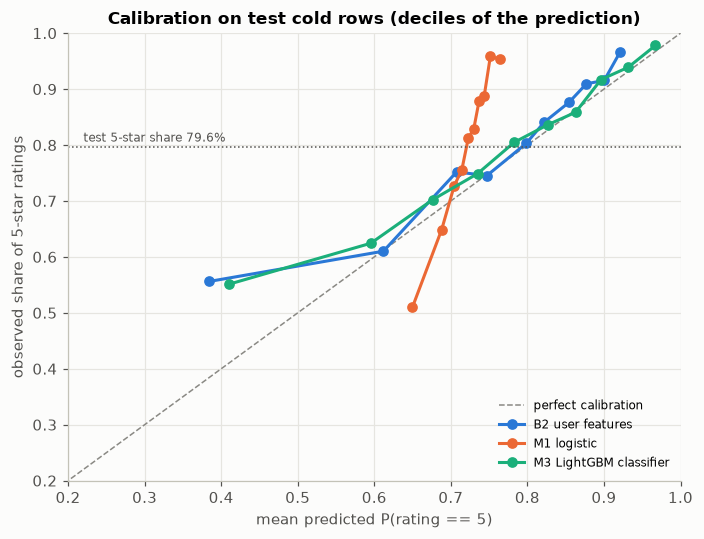

5-star share: pseudo-cold training rows 72.6% (weighted 70.7%); test cold rows 79.6%
mean prediction on test cold rows: B0 constant 0.707, B2 user features 0.761, M1 logistic 0.720, M3 LightGBM classifier 0.768


In [20]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 1], [0, 1], color=P.GRAY, linestyle="--", linewidth=1, label="perfect calibration")
for color, name in zip(P.SERIES, ["B2 user features", "M1 logistic", "M3 LightGBM classifier"]):
    s = test_bin[name][test_cold]
    g = pd.DataFrame({"pred": s, "obs": yb}).groupby(pd.qcut(s, 10, duplicates="drop"), observed=True).mean()
    ax.plot(g["pred"], g["obs"], "o-", color=color, label=name, markersize=6)
ax.axhline(yb.mean(), color=P.INK, linestyle=":", linewidth=1)
ax.text(0.22, yb.mean() + 0.01, f"test 5-star share {yb.mean():.1%}", fontsize=8, color=P.INK)
ax.set_xlim(0.2, 1); ax.set_ylim(0.2, 1)
ax.set_xlabel("mean predicted P(rating == 5)")
ax.set_ylabel("observed share of 5-star ratings")
ax.set_title("Calibration on test cold rows (deciles of the prediction)")
ax.grid(True, axis="both")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print(f"5-star share: pseudo-cold training rows {final_rows.y.mean():.1%} (weighted {p0_final:.1%}); test cold rows {yb.mean():.1%}")
print("mean prediction on test cold rows:", ", ".join(f"{n} {test_bin[n][test_cold].mean():.3f}" for n in final_bin))

B2 and the M3 classifier are **slightly too pessimistic**: in almost every bin the observed share of 5-star ratings is above the prediction, and their average prediction (0.76–0.77) is below the actual 79.6%. The cause is a shift in the base rate: pseudo-cold training rows are 5 stars 72.6% of the time (70.7% with the 1/√n_u weights), while test cold rows are 79.6%. The M3 classifier is the closest to the diagonal.

The logistic M1 is **badly calibrated**: its predictions only span 0.65–0.76 while the observed rates go from 0.51 to 0.96, and its average prediction is 0.72. This is the price of the very strong penalty chosen by AUC. The ordering is still right (the curve rises steadily), so AUC is unaffected, but its outputs should not be read as probabilities. Two fixes, both tuned on validation: choose C by log loss instead of AUC, or recalibrate the output (Platt scaling or an intercept shift on the validation cold rows); the same intercept shift would also correct the small bias of B2 and M3.

### Takeaways for the binary version

- **AUC is the more sensitive metric here.** The main models gain about +0.01 AUC over B2 on test, which is significant, while their MSE gain is not.
- **Rating target vs. binary target:** no significant difference in AUC, so the 1–5 rating is a sound choice for the main task.
- **Tuning by AUC ignores calibration.** The M3 classifier gives the best AUC and log loss; the logistic M1, tuned for AUC, ranks well but its probabilities are compressed. All models are a little too low on average because 5-star ratings are more common in the evaluation rows than in the first-review training rows.